# 03. Replicating the main effect
**Goal**: Recompute the main analyses of the HeartSteps V1 paper with the same method. If the results match, the table built in 01 and the method can be trusted, and 04 can extend the same model.

**Questions**
1. On average, do notifications increase steps in the next 30 minutes?
2. Does the effect shrink over the study?
3. Does the effect differ by location (home or work vs elsewhere)?
4. Do walking and anti-sedentary notifications differ? (no reference number; an extension for 04)
5. Do conclusions hold with a different treatment of missing steps?


## 0. Setup

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [3]:
pd.set_option("display.max_columns", None) # 열 생략X

# This notebook lives in notebooks/, so the project folder is one level up.
PROJECT_DIR = Path("..")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

BLUE = "#2a78d6"
GREY = "#9a9893"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.axisbelow": True,
})

decision_points = pd.read_csv(PROCESSED_DIR / "decision_points.csv")
print(decision_points.shape)

(8274, 31)


### 0.1. Analysis sample and day in study
- Use available decision points and leave out travel days, as the paper does. Rows with missing steps stay for now, because sections 1 and 5 compare ways of handling them.
- The paper counts days in the study from 0 to 41. `study_day` from 01 counts calendar days, including travel days. So the non-travel days are numbered again from 0 (`day_in_study`). 
- Only travel days should be skipped, so the count is made **before** the availability filter.

In [ ]:
not_travel = decision_points[decision_points["travel_day"] == 0].copy()     # 여행x 행만 남김
not_travel["day_in_study"] = not_travel.groupby("user_id")["study_day"].rank(method="dense") - 1    # 여행일수 제외하고 연구일수를 다시 계산

sample = not_travel[not_travel["available"] == 1].copy() # 가용만 남김

print(f"Decision points: {len(sample)}")
print(f"Participants: {sample['user_id'].nunique()}")
print(f"Last day in study per participant: {sample.groupby('user_id')['day_in_study'].max().min():.0f} to {sample.groupby('user_id')['day_in_study'].max().max():.0f}")

Decision points: 6331
Participants: 37
Last day in study per participant: 35 to 51


### 0.2. Method

The same regression as the paper:

`log steps after ~ log steps before + sent`

- The coefficient of `sent` is the effect; `(exp(coef) - 1) x 100` turns it into a percentage, as in 02.
- Steps before do not bias the effect (thanks to randomization); they explain how active a person already is and make the estimate more precise.
- One person gives many decision points, so standard errors are computed per person. The paper's method (WCLS) equals this GEE when the send probability is a constant 0.6.
- With only 37 participants, standard errors tend to be too small, so they are corrected as in the paper.
- The function below fits the model and returns the estimate, standard error, p-value, and 95% confidence interval for each term. It is a function because the same kind of model is fitted several times.

In [5]:
def fit_gee(formula, data):
    model = smf.gee(
        formula,
        groups="user_id",                         # standard errors per participant
        data=data,
        cov_struct=sm.cov_struct.Independence(),  # 계수(추정값)를 구할 때는 일반 회귀처럼 각 행을 똑같이 다루라는 설정
        missing="drop",                           # skip rows with a missing value in the formula(식에 들어간 열 중 하나라도 비어 있는 행은 빼고 계산)
    )
    result = model.fit(cov_type="bias_reduced")   # small-sample correction, bias_reduced는 소표본 보정
    ci = result.conf_int()
    table = pd.DataFrame({
        "estimate": result.params,  # 계수(추정값)
        "std_err": result.bse,  # 표준오차
        "p_value": result.pvalues,  # p값
        "ci_low": ci[0],    # 95% 신뢰구간 하한    
        "ci_high": ci[1],   # 95% 신뢰구간 상한
    })
    return table.round(3)

---

## 1. Average Effect
- About 9% of the outcome is missing (section 4 of 02). 
- The raw data also ships a version with missing steps set to 0 (`jbsteps30.zero`), so 01 kept both. Estimate the average effect with each and compare with the paper.
- **Paper**: estimate 0.131, p = 0.060, about 14% more steps

In [6]:
versions = {
    "missing set to 0": ("log_steps_post30_zero", "log_steps_pre30_zero"),
    "missing left out": ("log_steps_post30", "log_steps_pre30"),
}

average = {}
for name, (outcome, pre) in versions.items():
    table = fit_gee(f"{outcome} ~ {pre} + sent", sample)
    row = table.loc["sent"].copy()
    row["n_rows"] = sample[[outcome, pre]].notna().all(axis=1).sum()   # rows the model used, 두 값이 모두 있는 행 수
    average[name] = row

average = pd.DataFrame(average).T
average["n_rows"] = average["n_rows"].astype(int) # 모형이 실제로 쓴 행 수를 붙임
average["effect_pct"] = ((np.exp(average["estimate"]) - 1) * 100).round(1) 
average

,estimate,std_err,p_value,ci_low,ci_high,n_rows,effect_pct
missing set to 0,0.132,0.067,0.050,0.000,0.263,6331,14.1
missing left out,0.154,0.075,0.041,0.006,0.301,5552,16.6


- The version with missing set to 0 matches the paper (0.132 vs 0.131), so the paper most likely used it; sections 2-4 use this version. The other version is used in section 5 to check that conclusions hold.
- The p-value is 0.050, slightly smaller than the paper's 0.060, probably because the small-sample correction is not exactly the same. Both read as "borderline significant".

In [7]:
OUTCOME = "log_steps_post30_zero"
PRE = "log_steps_pre30_zero"

average_table = fit_gee(f"{OUTCOME} ~ {PRE} + sent", sample)
average_table

,estimate,std_err,p_value,ci_low,ci_high
Intercept,1.701,0.124,0.00,1.457,1.945
log_steps_pre30_zero,0.411,0.031,0.00,0.351,0.471
sent,0.132,0.067,0.05,0.000,0.263


- sent 0.132: 알림을 보내면 30분 걸음 수가 약 14% 많음. p = 0.05라 통계적으로 경계선.
- log_steps_pre30_zero 0.411: 알림 전에 많이 걷던 시점은 알림 후에도 많이 걸음. 효과를 해석하는 항은 아니고, 이 차이를 설명해서 sent 추정을 더 정확하게 만드는 역할.
- Intercept 1.701: 알림 전 걸음 수가 0(로그 기준)이고 알림을 안 보냈을 때의 기준값. 해석할 필요는 없음.

---

## 2. Change over the study
Adding the `sent:day_in_study` term shows how the effect changes each day.
- `sent`: the effect on the first day (day 0)
- `sent:day_in_study`: the change in the effect per day
- `day_in_study`: the change in steps per day regardless of notifications (included so it is not mixed into the effect)

**Paper**: day 0: 0.507 (about 66% more steps); per day: -0.018 (p = 0.005)

In [8]:
# 알림 효과가 연구 기간이 지나면서 어떻게 변하는지

day_table = fit_gee(f"{OUTCOME} ~ {PRE} + day_in_study + sent + sent:day_in_study", sample)
day_table

,estimate,std_err,p_value,ci_low,ci_high
Intercept,1.737,0.135,0.000,1.473,2.001
log_steps_pre30_zero,0.409,0.030,0.000,0.351,0.468
day_in_study,-0.001,0.005,0.777,-0.012,0.009
sent,0.463,0.142,0.001,0.184,0.742
sent:day_in_study,-0.016,0.006,0.005,-0.026,-0.005


The effect on day d is `sent + sent:day_in_study x d`. It reaches 0 on day `-sent / sent:day_in_study`.

Effect on day 0: 58.9%
Effect reaches 0 around day 29


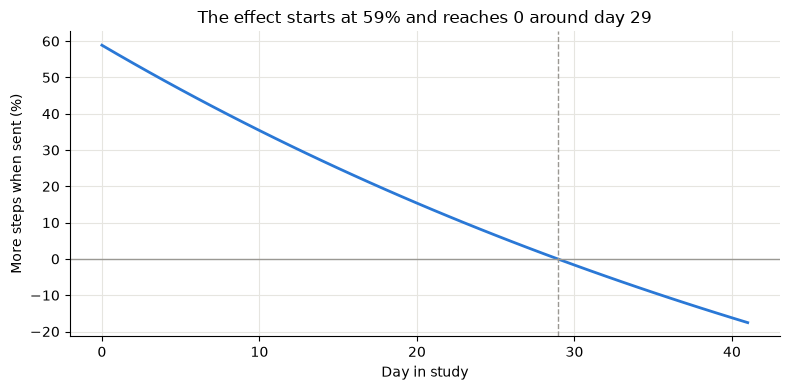

In [9]:
effect_day0 = day_table.loc["sent", "estimate"]
change_per_day = day_table.loc["sent:day_in_study", "estimate"]

days = np.arange(0, 42)     # 42개의 날짜 생성
effect_by_day = (np.exp(effect_day0 + change_per_day * days) - 1) * 100
zero_day = -effect_day0 / change_per_day

print(f"Effect on day 0: {(np.exp(effect_day0) - 1) * 100:.1f}%")
print(f"Effect reaches 0 around day {zero_day:.0f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(days, effect_by_day, color=BLUE, linewidth=2)
ax.axhline(0, color=GREY, linewidth=1)
ax.axvline(zero_day, color=GREY, linestyle="--", linewidth=1)
ax.set_xlabel("Day in study")
ax.set_ylabel("More steps when sent (%)")
ax.set_title(f"The effect starts at {(np.exp(effect_day0) - 1) * 100:.0f}% and reaches 0 around day {zero_day:.0f}")
plt.tight_layout()
plt.show()

- The chart assumes a straight-line decline. Its direction agrees with the simple weekly comparison in 02 (+86% in week 1, then up and down from week 4).
- The part below 0 comes from the straight-line assumption, so it should not be read as "notifications reduce steps".

---

## 3. Difference by location
- The paper compares the effect at home or work (`home_work` = 1) with elsewhere (0); a missing location counts as 0. Each notification type is analyzed separately, keeping only decision points with that type or no notification.

- The `active:home_work` term is how much larger the effect is at home or work.

- **Paper**: walking: 0.377 (p = 0.049); anti-sedentary: not significant

In [10]:
# 집이나 직장이 아니면 0
sample["home_work"] = sample["location"].isin(["home", "work"]).astype(int)
sample["active"] = (sample["send_type"] == "active").astype(int)        # active: 걷기 알림을 보냈으면 1
sample["sedentary"] = (sample["send_type"] == "sedentary").astype(int)  # sedentary: 앉아 있기 줄이기 알림을 보냈으면 1

walk_vs_none = sample[sample["send_type"].isin(["active", "none"])]     # 걷기 알림을 보낸 시점과 아무 알림도 안 보낸 시점만 남김
sedentary_vs_none = sample[sample["send_type"].isin(["sedentary", "none"])]     # 앉아 있기 줄이기 알림과 안 보낸 시점만 남김

print(sample["home_work"].value_counts())
print(f"Walking vs none: {len(walk_vs_none)} rows, anti-sedentary vs none: {len(sedentary_vs_none)} rows")

home_work
0    3589
1    2742
Name: count, dtype: int64
Walking vs none: 4675 rows, anti-sedentary vs none: 4231 rows


In [11]:
walk_table = fit_gee(f"{OUTCOME} ~ {PRE} + home_work + active + active:home_work", walk_vs_none)
walk_table

,estimate,std_err,p_value,ci_low,ci_high
Intercept,1.668,0.134,0.000,1.405,1.931
log_steps_pre30_zero,0.415,0.031,0.000,0.354,0.476
home_work,0.054,0.130,0.681,-0.202,0.309
active,0.052,0.103,0.613,-0.149,0.253
active:home_work,0.378,0.181,0.037,0.023,0.733


In [12]:
sedentary_table = fit_gee(f"{OUTCOME} ~ {PRE} + home_work + sedentary + sedentary:home_work", sedentary_vs_none)
sedentary_table

,estimate,std_err,p_value,ci_low,ci_high
Intercept,1.688,0.138,0.000,1.418,1.958
log_steps_pre30_zero,0.408,0.031,0.000,0.346,0.469
home_work,0.052,0.131,0.693,-0.206,0.309
sedentary,0.079,0.128,0.535,-0.171,0.329
sedentary:home_work,-0.115,0.188,0.540,-0.484,0.253


- Walking notifications: almost no effect elsewhere (`active`), larger at home or work (`active:home_work`), close to the paper.
- Anti-sedentary notifications: no significant difference by location, as in the paper.

---

## 4. Effect by notification type
- Section 3 looked at location. Here the average effects of the two types are compared in one model, regardless of location. `active` and `sedentary` are each compared with no notification. 
- The 1 notification with no recorded type (`unknown`) is left out. No reference number was found for this, so it is an extension for 04.

In [14]:
type_sample = sample[sample["send_type"] != "unknown"] # unknown행 제외
type_table = fit_gee(f"{OUTCOME} ~ {PRE} + active + sedentary", type_sample)
type_table["effect_pct"] = ((np.exp(type_table["estimate"]) - 1) * 100).round(1)
type_table.loc[["active", "sedentary"]]

,estimate,std_err,p_value,ci_low,ci_high,effect_pct
active,0.211,0.083,0.011,0.049,0.374,23.5
sedentary,0.029,0.091,0.754,-0.150,0.207,2.9


- The average effect comes mostly from walking notifications; anti-sedentary notifications barely increase 30-minute steps.
- Anti-sedentary notifications ask for a short break from sitting, which 30-minute step counts may not capture. So the reading is "no effect visible in this outcome", not "no effect".

---

## 5. Sensitivity analysis
- Recompute the key results of sections 1-3 with missing steps left out. 
- If both versions agree in direction and size, the way missing values are handled does not change the conclusions.

In [15]:
rows = []
for name, (outcome, pre) in versions.items():
    average_result = fit_gee(f"{outcome} ~ {pre} + sent", sample)
    day_result = fit_gee(f"{outcome} ~ {pre} + day_in_study + sent + sent:day_in_study", sample)
    walk_result = fit_gee(f"{outcome} ~ {pre} + home_work + active + active:home_work", walk_vs_none)
    rows.append({
        "version": name,
        "average: sent": average_result.loc["sent", "estimate"],
        "average: p": average_result.loc["sent", "p_value"],
        "day 0: sent": day_result.loc["sent", "estimate"],
        "per day: sent:day": day_result.loc["sent:day_in_study", "estimate"],
        "per day: p": day_result.loc["sent:day_in_study", "p_value"],
        "walking: active:home_work": walk_result.loc["active:home_work", "estimate"],
        "walking: p": walk_result.loc["active:home_work", "p_value"],
    })

sensitivity = pd.DataFrame(rows).set_index("version").T
sensitivity

version,missing set to 0,missing left out
average: sent,0.132,0.154
average: p,0.050,0.041
day 0: sent,0.463,0.447
per day: sent:day,-0.016,-0.014
per day: p,0.005,0.012
walking: active:home_work,0.378,0.332
walking: p,0.037,0.103


- The average effect and the decline over time are similar in size and significance in both versions. -> These conclusions do not depend on how missing values are handled.
- The location difference for walking notifications is similar in direction and size (0.378 vs 0.332), but not significant when missing values are left out (p = 0.103). -> Treat this as weak evidence and check it again with other context variables in 04.

---

## 6. Comparison with the paper
Paper values: the HeartSteps V1 example in Qian et al. (2022).

In [16]:
comparison = pd.DataFrame({
    "paper": [0.131, 0.507, -0.018, 0.377], # 논문값
    "this notebook": [
        average_table.loc["sent", "estimate"],
        day_table.loc["sent", "estimate"],
        day_table.loc["sent:day_in_study", "estimate"],
        walk_table.loc["active:home_work", "estimate"],
    ],
}, index=[
    "average effect (sent)",
    "effect on day 0 (sent)",
    "change per day (sent:day_in_study)",
    "walking, home or work (active:home_work)",
])
comparison["difference"] = (comparison["this notebook"] - comparison["paper"]).round(3)
comparison

,paper,this notebook,difference
average effect (sent),0.131,0.132,0.001
effect on day 0 (sent),0.507,0.463,-0.044
change per day (sent:day_in_study),-0.018,-0.016,0.002
"walking, home or work (active:home_work)",0.377,0.378,0.001


- The average effect and the location difference for walking notifications are almost the same.
- The change over time is slightly smaller (0.463 vs 0.507 on day 0), probably because days are not counted exactly as in the paper (the paper uses days 0-41; here some participants go past day 41). Direction and significance are the same.
- -> The table from 01 and this method reproduce the paper's results. 04 uses the same model.

## 7. Summary

| 질문 / Question | 답 / Answer | 다음 단계 / Next |
| --- | --- | --- |
| 평균 효과가 있나? / Is there an average effect? | 약 +14%, p = 0.05로 경계선. 논문과 같음 / About +14%, borderline (p = 0.05), same as the paper | 평균만으로는 약하므로 상황별로 나눠 본다 / The average alone is weak, so split by situation (04) |
| 시간에 따라 줄어드나? / Does it shrink? | 첫날 약 +59%, 약 29일째 0 / About +59% on day 0, 0 around day 29 | 07에서 알림 빈도 조절의 근거 / Basis for adjusting frequency in 07 |
| 장소에 따라 다른가? / Does location matter? | 걷기 알림은 집·직장에서 효과가 큼(논문과 같음). 다만 근거는 약함(5절) / Walking notifications work better at home or work, as in the paper, but the evidence is weak (section 5) | 04에서 시간대·요일·날씨까지 확장 / 04 adds time slot, day type, and weather |
| 종류에 따라 다른가? / Does type matter? | 효과는 주로 걷기 알림에서 나옴 / The effect comes mostly from walking notifications | 04에서 종류별로 상황 분석 / 04 analyzes situations by type |
| 결측 처리를 바꿔도 같은가? / Robust to missing values? | 평균 효과와 시간 감소는 같음. 장소 차이는 결측을 빼면 유의하지 않음 / Same for the average effect and decline; the location difference is not significant with missing values left out | 04도 0으로 채운 버전을 쓰고 결측 제외 버전으로 확인 / 04 uses the same main version and checks the other |